# 02 - Keyword Cleaning & EDA

Loads `raw_articles.pkl` and applies keyword cleaning.
All optional steps can be turned on/off independently.

In [1]:
import pandas as pd
import re
import unicodedata
import matplotlib.pyplot as plt
from collections import Counter
from pathlib import Path
from wordcloud import WordCloud

from pathlib import Path

# Robust root detection — works whether notebook is run from project root or notebooks/
_cwd = Path.cwd()
PROJECT_ROOT = _cwd if (_cwd / "big_data").exists() else _cwd.parent

BIG_DATA  = PROJECT_ROOT / "big_data"
DATA_DIR  = PROJECT_ROOT / "data"
PLOTS_DIR = PROJECT_ROOT / "plots"
MODELS_DIR = PROJECT_ROOT / "models"
PLOTS_DIR.mkdir(exist_ok=True)
MODELS_DIR.mkdir(exist_ok=True)

PICKLE_IN  = BIG_DATA / 'baseline' / 'pickle' / 'raw_articles.pkl'
PICKLE_OUT = BIG_DATA / 'baseline' / 'pickle' / 'clean_articles.pkl'

df_raw = pd.read_pickle(PICKLE_IN)
print(f"Loaded: {df_raw.shape[0]} articles, {df_raw.shape[1]} columns")
df_raw.head(2)

Loaded: 10588 articles, 16 columns


,filename,pmcid,doi,journal,year,authors,title,keywords,abstract,introduction,methods,results,discussion,conclusion,tables,metadata_junk
0,PMC1592647.xml,PMC1592647,10.1084/jem.20031051,The Journal of Experimental Medicine,2003,Berg Rance E.; Crossley Emily; Murray Sean; Fo...,Memory CD8 + T Cells Provide Innate Immune Pro...,IFN-γ; Listeria monocytogenes; T lymphocytes; ...,Interferon (IFN)-γ plays an important role in ...,The immune response against pathogenic microor...,"C57BL/6J (B6), C57BL/6.PL-Thy1 a /Cy (B6.Thy1....",We demonstrated previously that a population o...,CD8 + T cells play an important role in the co...,,[],
1,PMC1697748.xml,PMC1697748,10.1093/ecam/nel073,Evidence-based Complementary and Alternative M...,2006,Epstein O. I.; Pavlov I. F.; Shtark M. B.,Improvement of Memory by Means of Ultra-Low Do...,"Antigen S-100B; antibodies; ultra-low doses, m...","Antigen S-100B of nervous tissue, according to...",There is a constant interest in modern neuroph...,To prepare potentiated antibodies rabbit monos...,In the experiment on development of inhibitory...,The rats that were administered antibodies on ...,,[**Latencies of rats' descent from the platfor...,\n[unmapped: stimulation and registration of r...


In [2]:
# =============================================================================
# POST-PICKLE ARTEFACT CLEANING
# =============================================================================

# 1. AUTHOR ARTEFACTS
# data_extraction.py used str(xpath_list) which produced "['Smith'] ['John']" repr.
# Fixed at source in v3 — but existing pickles still need post-processing.
df_raw['authors'] = df_raw['authors'].str.replace(r"\['|'\]", "", regex=True)

# 2. MOJIBAKE (encoding artefacts)
# These appear because some XML content was re-encoded from UTF-8 → latin-1 and back.
# Common patterns found in xml_attr_frequencies.csv:
#   â€"  → –  (U+2013 en-dash,  UTF-8: 0xE2 0x80 0x93 misread as latin-1)
#   â€"  → —  (U+2014 em-dash,  UTF-8: 0xE2 0x80 0x94)
#   Â±   → ±  (U+00B1 plus-minus, UTF-8: 0xC2 0xB1 misread as latin-1)
#   Â·   → ·  (U+00B7 middle dot)
#   â‰¤  → ≤  (U+2264 less-than-or-equal)
#   â€˜  → '  (U+2018 left single quote)
#   â€™  → '  (U+2019 right single quote)

MOJIBAKE = {
    'â€"':  '–',
    'â€"':  '—',
    'Â±':   '±',
    'Â·':   '·',
    'â‰¤':  '≤',
    'â‰¥':  '≥',
    'â€˜':  '‘',
    'â€™':  '’',
    'â€œ':  '"',
    'â€': '"',
    'Ã©':   'é',
    'Ã¼':   'ü',
    'Ã¶':   'ö',
    'Ã¤':   'ä',
    'Ã': 'ß',
    'Â ': ' ',   # non-breaking space
}

def fix_mojibake(text: str) -> str:
    if not isinstance(text, str):
        return text
    for bad, good in MOJIBAKE.items():
        text = text.replace(bad, good)
    return text

# Apply to all text columns
TEXT_COLS = ['title', 'abstract', 'introduction', 'methods',
             'results', 'discussion', 'conclusion', 'keywords', 'authors']

for col in TEXT_COLS:
    if col in df_raw.columns:
        df_raw[col] = df_raw[col].apply(fix_mojibake)

print("Artefact cleaning done.")
df_raw.iloc[1000:1004, 0:8].T


Artefact cleaning done.


,1000,1001,1002,1003
filename,PMC4236802.xml,PMC4238399.xml,PMC4239771.xml,PMC4241610.xml
pmcid,PMC4236802,PMC4238399,PMC4239771,PMC4241610
doi,,10.1111/tpj.12299,10.4103/1673-5374.143427,
journal,Journal of Medical Signals and Sensors,The Plant Journal,Neural Regeneration Research,Dental Research Journal
year,2014,2013,2014,2014
authors,Jafari Zohreh; Edrisi Mehdi; Marateb Hamid Reza,Tobimatsu Yuki; Wagner Armin; Donaldson Lloyd;...,Zhang Yanru; Zhang Hui; Zhang Gechen; Ka Ka; H...,Kuştarci Alper; Arslan Dilara; Altunbaş Demet
title,An Electromyographic-driven Musculoskeletal To...,Visualization of plant cell wall lignification...,Combining acellular nerve allografts with brai...,In vitro comparison of working length determin...
keywords,Electromyography; musculoskeletal model; neuro...,Arabidopsis thaliana; Pinus radiata; cell wall...,bone marrow mesenchymal stem cells; brain-deri...,DentaPort ZX; Endo Master; Raypex 5; electroni...


## 1 - clean_text helper

In [3]:
def clean_text(text: str) -> str:
    """
    Normalise text for NLP:
    1. Unicode NFKD normalisation: decomposes characters (é → e + combining accent)
    2. ASCII encoding: drops non-ASCII (accents, special chars) — safe after mojibake fix
    3. Decimal point protection: preserves numbers like 3.14 through the cleaning
    4. Remove remaining non-alphanumeric characters (except decimal points)
    5. Normalise whitespace

    Note: mojibake artefacts (â€", Â±, etc.) are fixed BEFORE this step
    in the post-pickle cleaning cell above, so they are correctly converted
    rather than silently dropped here.
    """
    if not isinstance(text, str) or not text:
        return ""
    text = unicodedata.normalize('NFKD', text)
    text = text.encode('ascii', 'ignore').decode('ascii')
    text = re.sub(r'(\d)\.(\d)', r'\1T1E2M3P4\2', text)
    text = re.sub(r'[^a-zA-Z0-9\s]', ' ', text)
    text = text.replace('T1E2M3P4', '.')
    text = re.sub(r'\s+', ' ', text).strip()
    return text

## 2 - Keyword Cleaning

**first: simple** 

blacklist only - no subj-group splitting yet.
Enable splitting later if baseline F1 is poor.

In [4]:
import re
import unicodedata

# =============================================================================
# KEYWORD CLEANING PIPELINE
# Applied BEFORE clean_text() / ASCII normalisation
# =============================================================================

# Greek letter ranges (Unicode) - filter BEFORE ASCII normalisation
GREEK_PATTERN = re.compile(r'^[α-ωΑ-Ω]')  # α-ω, Α-Ω

def is_abbrev_expansion(kw):
    # Filter 'dmem, dulbecco s modified eagle s medium' style entries
    # Keeps standalone abbreviations like 'dmem', 'fmri', 'il-1'
    return bool(re.match(r'^[a-z0-9-]{2,6},\s+[a-z]', kw))

def is_iupac_or_junk(kw):
    # Starts with digit or bracket+digit
    if re.match(r'^[\(\[]?\d', kw):
        return True
    # Starts with dash+digit: '-2,3-diaminopropionyl'
    if re.match(r'^-\d', kw):
        return True
    # Too short
    if len(kw.strip()) <= 2:
        return True
    return False

# Pattern: 'Full Name (ABBREV)' or 'ABBREV (Full Name)' at end of string
# The trailing $ ensures we only match when () is the last element
_PAREN_RE   = re.compile(r'^(.*?),?\s*\(([^)]+)\)\s*$')
_PAREN_SKIP = re.compile(
    r'^(s|es)$'          # pluralization: disorder(s)
    r'|^pubchem'         # PubChem IDs
    r'|^cid\s*:'         # CID: references
    r'|^see\s'          # cross-references: (see X)
)

def expand_paren_abbrev(kw):
    """
    Split 'full name (abbrev)' or 'abbrev (full name)' into two keywords.

    Examples (input already lowercased):
      'functional magnetic resonance imaging (fmri)' → ['functional magnetic resonance imaging', 'fmri']
      'atrial fibrillation (af)'                     → ['atrial fibrillation', 'af']
      'sleep disorder(s)'                            → ['sleep disorder']
      '3-methyl-1-butanol (pubchem cid: 31260)'      → ['3-methyl-1-butanol']

    Skips: pluralizations, database IDs, cross-references.
    Numeric/IUPAC content is handled downstream by is_iupac_or_junk().
    """
    m = _PAREN_RE.match(kw)
    if not m:
        return [kw]
    outside = m.group(1).strip().rstrip(',').strip()
    inside  = m.group(2).strip()
    if not outside or _PAREN_SKIP.match(inside):
        return [outside] if outside else [kw]
    if inside == outside:
        return [outside]
    return [outside, inside]

# Minimum length for single-token purely-alphanumeric keywords (no hyphens, spaces).
# These are often ambiguous abbreviations produced by paren expansion.
#   = 3 → keep 'hiv', 'mri', 'eeg', 'tnf' (default, same as before)
#   = 4 → also drops 3-char codes: 'per', 'bid', 'ros', 'pcr', 'icu', 'tnf', 'mri', 'hiv'
#   = 5 → also drops 4-char codes: 'copd', 'egfr', 'fmri', 'gwas', 'ptsd', 'gaba'
MIN_STANDALONE_ALNUM_LEN = 3

_SINGLE_ALNUM_RE = re.compile(r'^[a-z0-9]+$')   # letters + digits only (no hyphen, no space)

def is_standalone_alnum_junk(kw):
    """
    Returns True if kw is a single purely-alphanumeric token (no hyphens)
    shorter than MIN_STANDALONE_ALNUM_LEN.
    Guards against overly short abbreviations slipping through after
    parenthetical expansion: e.g. 'bid', 'per', 'caw'.
    Already-filtered: len<=2 (is_iupac_or_junk).
    """
    if len(kw.split()) != 1:
        return False
    return _SINGLE_ALNUM_RE.match(kw) is not None and len(kw) < MIN_STANDALONE_ALNUM_LEN

def split_non_chemical(kw):
    # Do not split commas between digits: IUPAC '1,2-...'
    if re.search(r'\d\s*,\s*\d', kw):
        return [kw]
    return [p.strip() for p in kw.split(',') if p.strip()]

def parse_keywords(kwd_str):
    """
    Full keyword cleaning pipeline:
    1. Split by semicolon + lowercase
    2. Remove greek-prefixed keywords (BEFORE ASCII normalisation)
    3. Remove abbrev-expansion patterns
    4. Split remaining commas (skip chemical/IUPAC patterns)
    5. Remove IUPAC locants and junk
    6. Deduplicate, preserve order
    """
    if not isinstance(kwd_str, str):
        return []
    kws = [k.strip().lower() for k in kwd_str.split(';') if k.strip()]
    kws = [k for k in kws if not GREEK_PATTERN.match(k)]
    kws = [k for k in kws if not is_abbrev_expansion(k)]
    kws_flat = []
    for kw in kws:
        kws_flat.extend(split_non_chemical(kw))
    # Expand parenthetical abbreviations: 'full name (abbrev)' → two keywords
    # Keywords that come FROM expansion skip is_standalone_alnum_junk —
    # e.g. 'hiv' from 'human immunodeficiency virus (hiv)' must always be kept.
    # Keywords that were already standalone DO go through the alnum check.
    final_kws = []
    for kw in kws_flat:
        expanded = expand_paren_abbrev(kw)
        if len(expanded) > 1:
            # produced by expansion → keep both; only filter real IUPAC/junk
            for ek in expanded:
                if not is_iupac_or_junk(ek):
                    final_kws.append(ek)
        else:
            # original standalone keyword → apply full filter set
            ek = expanded[0]
            if not is_iupac_or_junk(ek) and not is_standalone_alnum_junk(ek):
                final_kws.append(ek)
    seen = set()
    result = []
    for k in final_kws:
        if k not in seen:
            seen.add(k)
            result.append(k)
    return result

# --- Noise filter (unchanged) ---
noise_words = {
    'research', 'article', 'articles', 'review', 'reviews',
    'original', 'study', 'paper', 'papers', 'report', 'reports',
    'investigation', 'chemistry', 'clinical', 'full',
    'dentistry', 'science',
}
noise_phrases = {
    'biological sciences', 'case report', 'original research',
    'original article', 'original investigation',
    'methods online', 'scientific papers', 'clinical science'
}

def filter_noise(kws):
    result = []
    for k in kws:
        k_words = set(k.split())
        if k not in noise_phrases and not any(n in k_words for n in noise_words):
            result.append(k)
    return result

# --- Apply pipeline ---
df = df_raw.copy()
df['kwd_lst'] = df['keywords'].apply(parse_keywords).apply(filter_noise)
df['kwd_lst_cl'] = df['kwd_lst'].apply(
    lambda kwds: list(dict.fromkeys([clean_text(k).lower() for k in kwds if clean_text(k).strip()]))
)

# --- Bigram enrichment ---
# For each article: find all consecutive 2-word sub-phrases within multi-word keywords
# that already exist as standalone keywords in the corpus → add as extra keywords.
# Example: 'deep neural network architecture' + corpus has 'neural network' → add it.
def _bigrams(kw):
    words = kw.split()
    return [' '.join(words[i:i+2]) for i in range(len(words) - 1)]

kw_flat = set(sum(df['kwd_lst_cl'], []))

def enrich_with_subkwds(kwds):
    kwd_set = set(kwds)
    extra = {
        bigram
        for kw in kwds if len(kw.split()) >= 3
        for bigram in _bigrams(kw)
        if bigram in kw_flat and bigram not in kwd_set
    }
    return kwds + sorted(extra)

df['kwd_lst_cl'] = df['kwd_lst_cl'].apply(enrich_with_subkwds)
df['n_keywords'] = df['kwd_lst_cl'].apply(len)

print(f"Articles with >= 1 keyword: {(df['n_keywords'] > 0).sum()}")

for i in range(5):
    orig = df['keywords'].iloc[i]
    clean = df['kwd_lst_cl'].iloc[i]
    print(f'\n--- Article {i} ---')
    print(f'  BEFORE: {str(orig)[:120]}')
    print(f'  AFTER : {clean}')


Articles with >= 1 keyword: 10570

--- Article 0 ---
  BEFORE: IFN-γ; Listeria monocytogenes; T lymphocytes; cytokines; innate immunity
  AFTER : ['ifn', 'listeria monocytogenes', 't lymphocytes', 'cytokines', 'innate immunity']

--- Article 1 ---
  BEFORE: Antigen S-100B; antibodies; ultra-low doses, memory
  AFTER : ['antigen s 100b', 'antibodies', 'ultra low doses', 'memory']

--- Article 2 ---
  BEFORE: locomotor activity; ovariectomized (OVX) rat; static magnetic fields (SMF); thermography
  AFTER : ['locomotor activity', 'ovariectomized ovx rat', 'static magnetic fields', 'smf', 'thermography']

--- Article 3 ---
  BEFORE: Chinese material medica; diabetes mellitus rat; hemorheology; insulin resistance; insulin secretion; insulin-like growth
  AFTER : ['chinese material medica', 'diabetes mellitus rat', 'hemorheology', 'insulin resistance', 'insulin secretion', 'insulin like growth factor ii', 'diabetes mellitus', 'growth factor']

--- Article 4 ---
  BEFORE: chaperone; conformat

## 3 - Keyword Frequency Filter

Filter by minimum corpus frequency. OCIS-coded keywords excluded. Articles with no remaining valid keywords are dropped.

In [5]:
# Flatten all cleaned keywords
lst_keys = [key for kws in df["kwd_lst_cl"].dropna() for key in kws if key]

keyword_counts = pd.Series(lst_keys).value_counts()

print(f"Total unique      : {len(keyword_counts)}")
print(f"After min_freq=2  : {(keyword_counts >= 2).sum()}")
print(f"After min_freq=10 : {(keyword_counts >= 10).sum()}")
print(f"After min_freq=20 : {(keyword_counts >= 20).sum()}")

Total unique      : 30583
After min_freq=2  : 6953
After min_freq=10 : 705
After min_freq=20 : 261


In [6]:
# Tradeoff: keywords retained vs articles lost per threshold
for mf in [5, 10, 20]:
    valid = set(keyword_counts[keyword_counts >= mf].index)
    valid_no_ocis = {k for k in valid if not re.match(r"^\d+\.\d+", k)}
    empty = df["kwd_lst_cl"].apply(
        lambda kws: len([k for k in kws if k in valid_no_ocis]) == 0 if isinstance(kws, list) else True
    ).sum()
    print(f"min_freq={mf:>2}: {len(valid_no_ocis):>5} keywords retained | {100*empty/len(df):.1f}% articles lost")

min_freq= 5:  1800 keywords retained | 14.6% articles lost
min_freq=10:   705 keywords retained | 27.3% articles lost
min_freq=20:   261 keywords retained | 43.3% articles lost


valid_keywords: 705
Articles dropped : 2886 (27.3%)
Articles retained: 7702


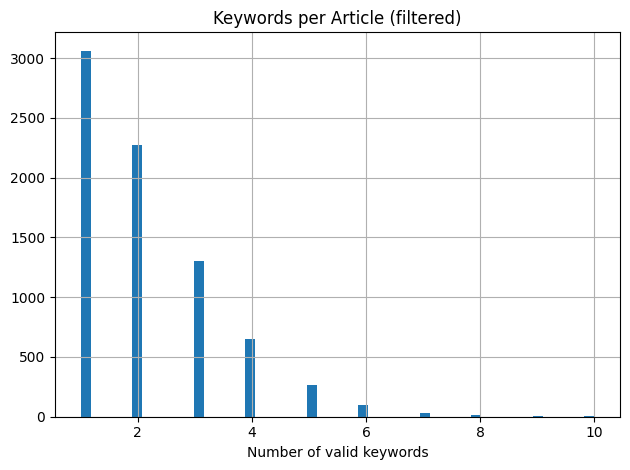

In [7]:
# Keywords with freq < 10 excluded: insufficient training samples per class
# -> class imbalance + overfitting risk
# OCIS-coded keywords (float prefix e.g. "170.6935 ...") excluded: journal-specific
min_freq = 10

valid_keywords = set(keyword_counts[keyword_counts >= min_freq].index)
valid_keywords = {k for k in valid_keywords if not re.match(r"^\d+\.\d+", k)}
print(f"valid_keywords: {len(valid_keywords)}")

df["keywords_filtered"] = df["kwd_lst_cl"].apply(
    lambda kws: [k for k in kws if k in valid_keywords] if isinstance(kws, list) else []
)

n_before = len(df)
df = df[df["keywords_filtered"].apply(len) > 0].copy()
print(f"Articles dropped : {n_before - len(df)} ({100*(n_before-len(df))/n_before:.1f}%)")
print(f"Articles retained: {len(df)}")

df["keywords_filtered"].apply(len).hist(bins=50)
plt.title("Keywords per Article (filtered)")
plt.xlabel("Number of valid keywords")
plt.tight_layout()
plt.show()

## 4 - EDA Plots

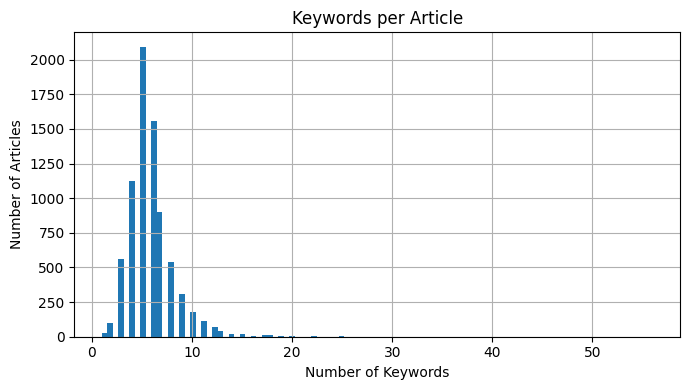

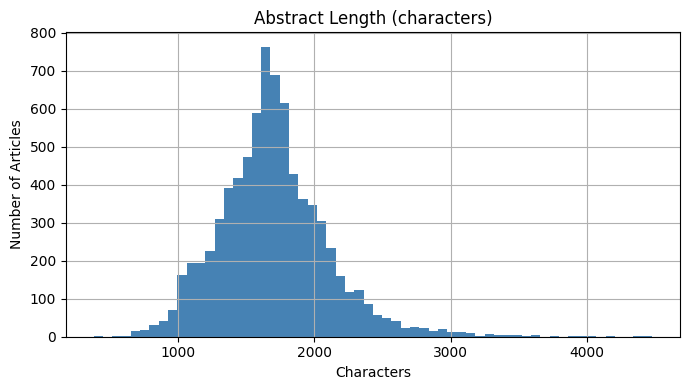

In [8]:
# Plot 1: Keywords per article
fig1, ax1 = plt.subplots(figsize=(7, 4))
df['n_keywords'].hist(bins=100, ax=ax1)
ax1.set_title('Keywords per Article')
ax1.set_xlabel('Number of Keywords')
ax1.set_ylabel('Number of Articles')
plt.tight_layout()
plt.savefig(PLOTS_DIR / "keyword_hist.png", dpi=150, bbox_inches='tight')
plt.show()

# Plot 2: Abstract length
fig2, ax2 = plt.subplots(figsize=(7, 4))
df['abstract'].apply(len).hist(bins=60, ax=ax2, color='steelblue')
ax2.set_title('Abstract Length (characters)')
ax2.set_xlabel('Characters')
ax2.set_ylabel('Number of Articles')
plt.tight_layout()
plt.savefig(PLOTS_DIR / "abstract_length_hist.png", dpi=150, bbox_inches='tight')
plt.show()

df[df['n_keywords'] > 20]['keywords'].to_csv('test.csv')

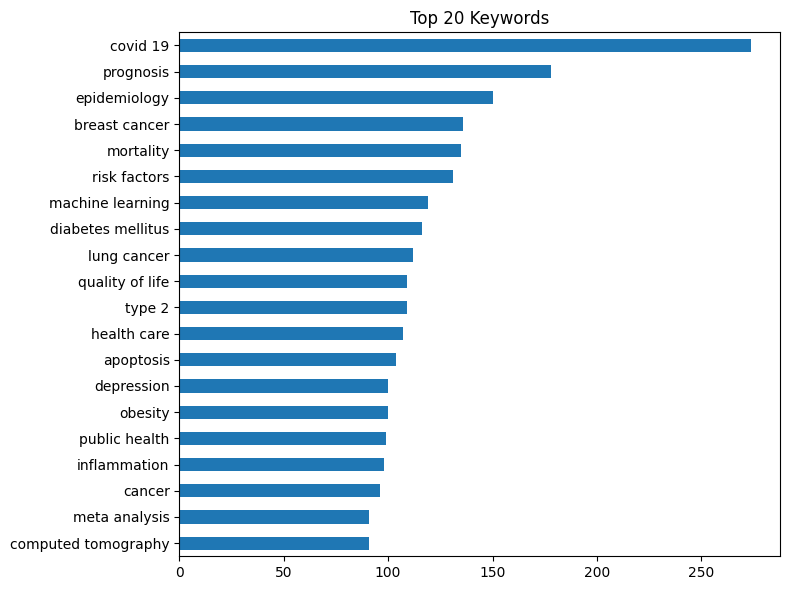

covid 19               274
prognosis              178
epidemiology           150
breast cancer          136
mortality              135
risk factors           131
machine learning       119
diabetes mellitus      116
lung cancer            112
type 2                 109
quality of life        109
health care            107
apoptosis              104
obesity                100
depression             100
public health           99
inflammation            98
cancer                  96
computed tomography     91
meta analysis           91
dtype: int64


In [9]:
# Top 20 keywords
all_kwds = [k for kwds in df['kwd_lst_cl'] for k in kwds]
top20 = pd.Series(dict(Counter(all_kwds).most_common(20)))
top20.sort_values().plot(kind='barh', figsize=(8, 6))
plt.title('Top 20 Keywords')
plt.tight_layout()
plt.show()
print(top20.sort_values(ascending=False))

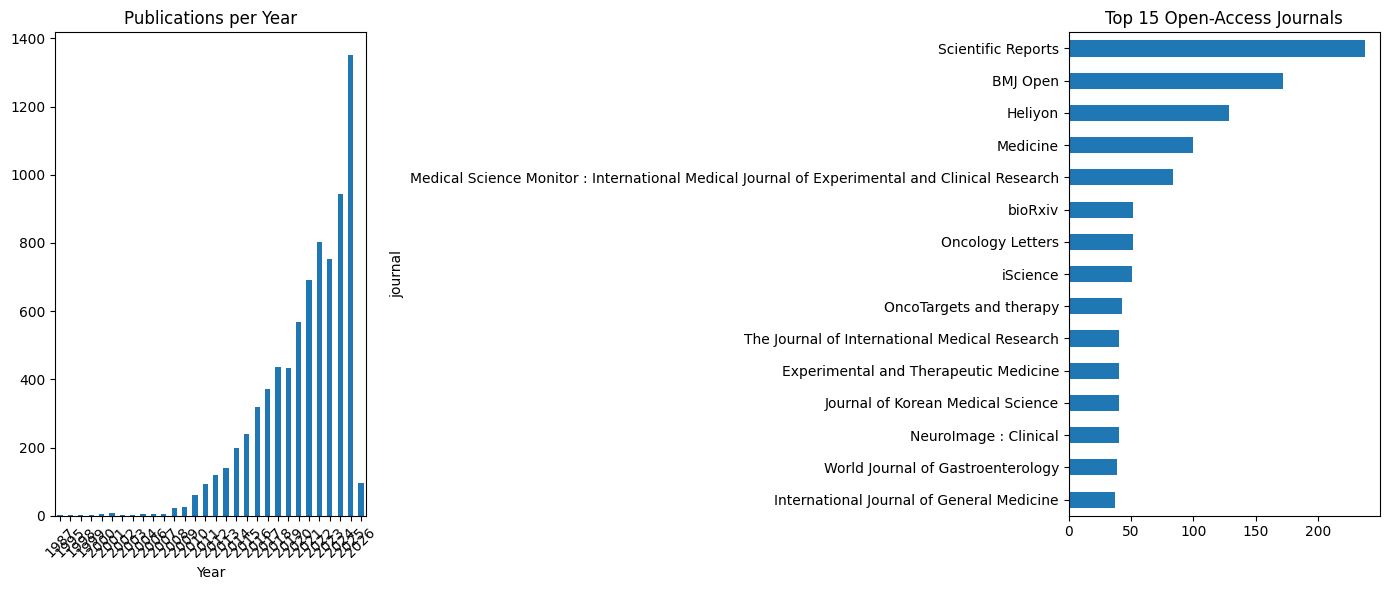

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Publications per year
df['year'].value_counts().sort_index().plot(kind='bar', ax=axes[0])
axes[0].set_title('Publications per Year')
axes[0].set_xlabel('Year')
axes[0].tick_params(axis='x', rotation=45)

# Top 15 journals
df['journal'].value_counts().head(15).sort_values().plot(kind='barh', ax=axes[1])
axes[1].set_title('Top 15 Open-Access Journals')

plt.tight_layout()
plt.show()

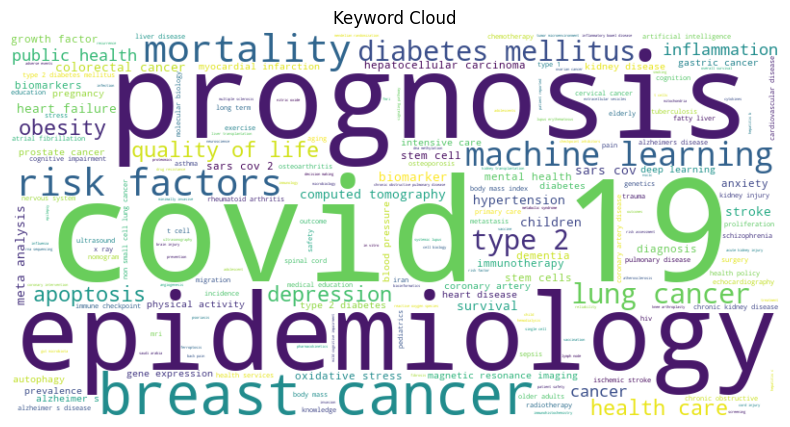

In [11]:
from wordcloud import WordCloud
from collections import Counter

all_kwds = [k for kwds in df['kwd_lst_cl'] for k in kwds]
freq = Counter(all_kwds)

wc = WordCloud(width=800, height=400, background_color='white')
wc.generate_from_frequencies(freq) 
plt.figure(figsize=(12, 5))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.title('Keyword Cloud')

plt.savefig(PLOTS_DIR / "wordcloud.png", dpi=150, bbox_inches='tight')
plt.show()

## 5 - Save Cleaned Pickle

Only run after reviewing EDA above.

In [12]:
SAVE_CLEAN_PICKLE = True   # set True to save

if SAVE_CLEAN_PICKLE:
    PICKLE_OUT.parent.mkdir(parents=True, exist_ok=True)
    df.to_pickle(PICKLE_OUT)
    print(f"Saved: {PICKLE_OUT}  ({len(df)} articles)")
else:

    print("SAVE_CLEAN_PICKLE = False - nothing written.")

Saved: c:\Users\<user>\bootcamps\CAPSTONE\Capstone1-text-prediction-for-scientific-papers\big_data\baseline\pickle\clean_articles.pkl  (7702 articles)
